# Demo
# Overview
- MNIST dataset
  + Goal: estimating summation of handwritten digit images
  + Input: a set of 28x28 images
  + Output: summation of given handwritten digit images
- Defining an CNN+LSTM for MNIST dataset
- Training and evaluating an CNN+LSTM

# Import libraries

In [1]:
import os

# Prevent loading two incompatible Intel OpenMP runtimes in the kernel.
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("MKL_NUM_THREADS", "2")

import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

torch.set_num_threads(2)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


# (1) Data

In [2]:
import gc
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets

gc.collect()

train_raw = datasets.MNIST(root="./data", train=True, download=True)
test_raw = datasets.MNIST(root="./data", train=False, download=True)

X_train_raw = train_raw.data.float() / 255.0
y_train_temp = train_raw.targets.float()
X_test_raw = test_raw.data.float() / 255.0
y_test_temp = test_raw.targets.float()

maxToAdd = 8
size = 28

class MnistSumSequenceDataset(Dataset):
    def __init__(self, images, labels, max_to_add=8, seed=2018):
        self.images = images
        self.labels = labels
        self.max_to_add = max_to_add
        self.n_samples = images.shape[0]

        rng = np.random.RandomState(seed)
        self.seq_indices = []
        self.targets = np.zeros((self.n_samples, 1), dtype=np.float32)
        for i in range(self.n_samples):
            num_to_add = int(np.ceil(rng.rand() * max_to_add))
            idx = rng.choice(self.n_samples, size=num_to_add)
            self.seq_indices.append(idx)
            self.targets[i, 0] = labels[idx].sum().item()

    def __len__(self):
        return self.n_samples

    def __getitem__(self, index):
        idx = self.seq_indices[index]
        seq = torch.zeros((self.max_to_add, 1, size, size), device=self.images.device)
        seq[:len(idx), 0, :, :] = self.images[idx]
        target = torch.tensor(self.targets[index], device=self.images.device)
        return seq, target

train_dataset = MnistSumSequenceDataset(X_train_raw, y_train_temp, max_to_add=maxToAdd, seed=2018)
test_dataset = MnistSumSequenceDataset(X_test_raw, y_test_temp, max_to_add=maxToAdd, seed=2019)

# Smaller batches reduce peak memory and native-library instability on CPU.
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

## Original data
- Input: 48x48 image
- Output: label (0, 1,..., 9)

## Data preprocessing
- Read images from MNIST
- Compute their summation

## New data
- Input: eight 48x48 images
- Output: summation of eight input images

# (2) Declare model

In [3]:
# Sau 3 lần MaxPool2d(2, 2) trên ảnh 28x28: 28 -> 14 -> 7 -> 3, với 128 channels => 128 * 3 * 3 = 1152
class MnistCnnLstm(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn_block = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(0.2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(0.2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(0.2),

            nn.Flatten()
        )
        cnn_out_dim = 128 * 3 * 3
        self.lstm1 = nn.LSTM(input_size=cnn_out_dim, hidden_size=64, batch_first=True)
        self.lstm_dropout = nn.Dropout(0.22)
        self.fc_out = nn.Linear(64, 1)

    def forward(self, x):
        # x: (B, T, C, H, W)
        b, t, c, h, w = x.shape
        x_flat = x.view(b * t, c, h, w)
        cnn_feat = self.cnn_block(x_flat)          # (B*T, 1152)
        seq_feat = cnn_feat.view(b, t, -1)         # (B, T, 1152)
        out1, _ = self.lstm1(seq_feat)            # (B, T, 64)
        last_step = self.lstm_dropout(out1[:, -1, :])
        return self.fc_out(last_step)

model = MnistCnnLstm().to(device)
print(model)
print("Total trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MnistCnnLstm(
  (cnn_block): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout2d(p=0.2, inplace=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.2, inplace=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout2d(p=0.2, inplace=False)
    (12): Flatten(start_dim=1, end_dim=-1)
  )
  (lstm1): LSTM(1152, 64, batch_first=True)
  (lstm_dropout): Dropout(p=0.22, inplace=False)
  (fc_out): Linear(in_features=64, out_features=1, bias=True)
)
Total trainable params: 404545


# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

In [4]:
lr = 0.01
epochs = 5
criterion = nn.L1Loss()  # mean_absolute_error
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

history = {"train_mae": [], "val_mae": []}
starting_time = time.time()

for epoch in range(1, epochs + 1):
    model.train()
    tr_loss, tr_total = 0.0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        preds = model(bx)
        loss = criterion(preds, by)
        loss.backward()
        optimizer.step()

        tr_loss += loss.item() * by.size(0)
        tr_total += by.size(0)

    model.eval()
    val_loss, val_total = 0.0, 0
    with torch.no_grad():
        for bx, by in test_loader:
            bx, by = bx.to(device), by.to(device)
            preds = model(bx)
            loss = criterion(preds, by)
            val_loss += loss.item() * by.size(0)
            val_total += by.size(0)

    epoch_tr_mae = tr_loss / tr_total
    epoch_val_mae = val_loss / val_total
    history["train_mae"].append(epoch_tr_mae)
    history["val_mae"].append(epoch_val_mae)

    print(f"Epoch {epoch:02d}/{epochs:02d} - loss (MAE): {epoch_tr_mae:.4f} - val_loss (MAE): {epoch_val_mae:.4f}")

print("> training time is %.4f minutes" % ((time.time() - starting_time) / 60))

Epoch 01/05 - loss (MAE): 5.5379 - val_loss (MAE): 3.1113
Epoch 02/05 - loss (MAE): 2.5651 - val_loss (MAE): 2.2701
Epoch 03/05 - loss (MAE): 1.9520 - val_loss (MAE): 1.3468
Epoch 04/05 - loss (MAE): 1.6972 - val_loss (MAE): 1.1030
Epoch 05/05 - loss (MAE): 1.5585 - val_loss (MAE): 1.0259
> training time is 40.9459 minutes


### Training time
- Training time with GTX 1080 is about 26.6267 minutes for 30 epochs
- Training time with Core i7 is around 808 minutes (~13.5 hours) for 30 epochs

# (4) Evaluate trained model

In [5]:
model.eval()
total_mae, total_samples = 0.0, 0
with torch.no_grad():
    for bx, by in test_loader:
        bx, by = bx.to(device), by.to(device)
        preds = model(bx)
        loss = criterion(preds, by)
        total_mae += loss.item() * by.size(0)
        total_samples += by.size(0)

score = total_mae / total_samples
print("Mean absolute error of testing set:", score)
del bx, by, preds, loss
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()

Mean absolute error of testing set: 1.0259233446121216


> actual summation = 12
> estimated summation = 13.475


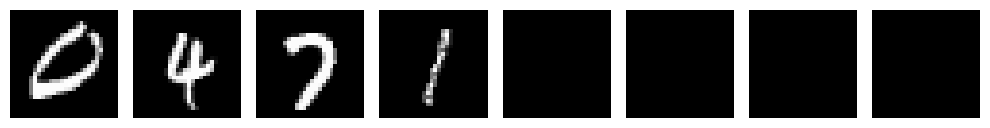

In [6]:
# Select a random test sequence and estimate summation
random_test_index = np.random.choice(len(test_dataset), size=1)[0]
test_seq, test_target = test_dataset[random_test_index]

plt.figure(figsize=(10, 5))
for indx in range(maxToAdd):
    plt.subplot(1, maxToAdd, indx + 1)
    test_img = test_seq[indx, 0, :, :].numpy()
    plt.axis("off")
    plt.imshow(test_img, cmap="gray")

model.eval()
with torch.no_grad():
    sample_input = test_seq.unsqueeze(0).to(device)
    est_sum = model(sample_input).item()

print("> actual summation = %d" % int(test_target.item()))
print("> estimated summation = %.3f" % est_sum)
plt.tight_layout()
plt.show()
plt.close("all")